# Escalamiento de características

**Equipo 39 · Proyecto Integrador MNA · Avance 2**

Esta sección explica cómo llevamos todas las magnitudes del problema a una escala comparable antes de estimar el módulo de Young. Se ejecuta completa de principio a fin (*Run All*) desde el repositorio, en unos segundos.

**En tres frases:**
1. En unidades del Sistema Internacional, una viga microscópica mezcla números de $10^{-23}$ (su momento de inercia) con números de $10^{11}$ (su módulo de Young), y eso hace casi imposible entrenar una red neuronal o ajustar un modelo.
2. En lugar de las técnicas de escalamiento habituales (min-max o estandarización), **adimensionalizamos**: dividimos cada cantidad entre una escala física de la propia viga, con lo que las ecuaciones conservan su forma y todo queda cerca de 1.
3. Además, las cantidades que recorren varios órdenes de magnitud, como la rigidez del anclaje, se trabajan en **escala logarítmica**.

**Contenido**
1. [El problema: magnitudes muy distintas](#1.-El-problema:-magnitudes-muy-distintas)
2. [La técnica: adimensionalizar](#2.-La-técnica:-adimensionalizar)
3. [Por qué no min-max ni estandarización](#3.-Por-qué-no-min-max-ni-estandarización)
4. [Transformación logarítmica de la rigidez del anclaje y de E](#4.-Transformación-logarítmica-de-la-rigidez-del-anclaje-y-de-E)
5. [Conclusión](#5.-Conclusión)

### Términos

| Término | Significado |
|---|---|
| **Módulo de Young, E** | Qué tan rígido es el material. Es lo que queremos estimar |
| **Voladizo / biempotrada** | Viga sujeta de un extremo (como un trampolín) / de los dos (como un puente) |
| **Forma modal, w(x)** | La forma que toma la viga al vibrar en uno de sus modos; su amplitud es arbitraria |
| **Momento flector, M** | El esfuerzo interno que dobla la viga |
| **Esfuerzo residual, σ₀** | Tensión o compresión que queda en la viga al fabricarla |
| **Rigidez del anclaje, k_θ y k_u** | Qué tanto cede el soporte al giro (k_θ) y al desplazamiento (k_u). Infinita = soporte perfecto |
| **Eigensolver** | Nuestro programa de referencia que calcula frecuencias y formas modales de una viga |
| **PINN** | Red neuronal informada por la física: se entrena para ajustar los datos y cumplir las ecuaciones de la viga a la vez |
| **Término de pérdida** | Cada parte del error que la PINN minimiza: ajuste a los datos y cumplimiento de cada ecuación |
| **Severidades s1–s6** | Seis niveles de anclaje cada vez más flexible en los datos sintéticos (s1 casi perfecto, s6 el más flexible) |
| **RM 8096** | Material de referencia del NIST (vigas de óxido de silicio) cuya geometría usamos |

### Preparación

Esta celda localiza el código del proyecto (`src/pinn_mems`) y carga las librerías. Requiere `numpy`, `scipy`, `pyyaml`, `matplotlib` y `pandas`.

In [1]:
import sys
from pathlib import Path

# Busca la raíz del repositorio subiendo desde la carpeta actual
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "pinn_mems").is_dir())
sys.path.insert(0, str(RAIZ / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pinn_mems import Soporte, Viga, cargar_config, generar, resolver_modos
from pinn_mems.adimensional import Escalas, desescalar, escalar
from pinn_mems.escalamiento import (
    elasticidad_kappa,
    magnitudes,
    ordenes_de_magnitud,
    terminos_de_perdida,
)

CONFIGS = RAIZ / "datos" / "sinteticos" / "configs"
pd.set_option("display.float_format", lambda v: f"{v:.3g}")

# Geometría de las vigas de óxido de RM 8096 (NIST SP 260-177)
VIGA = Viga(E=70e9, L=300e-6, b=28e-6, h=2.743e-6, rho=2200.0)
ESC = Escalas.desde_viga(VIGA)

## 1. El problema: magnitudes muy distintas

Tomamos un voladizo de 300 µm de largo, 28 µm de ancho y 2.7 µm de espesor, con la geometría del material de referencia del NIST, vibrando en su primer modo con una amplitud de 10 nm. La tabla muestra el tamaño típico de cada cantidad en unidades del Sistema Internacional (columna `si`) y en forma adimensional (columna `adimensional`; vacía para las cantidades que desaparecen al agruparse con otras).

In [2]:
tabla = pd.DataFrame(magnitudes(VIGA))
print(f"Órdenes de magnitud en SI: {ordenes_de_magnitud(tabla['si']):.0f}")
print(f"Órdenes de magnitud en forma adimensional: {ordenes_de_magnitud(tabla['adimensional'].dropna()):.1f}")
tabla

Órdenes de magnitud en SI: 33
Órdenes de magnitud en forma adimensional: 2.3


,cantidad,simbolo,unidad,si,adimensional
0,Longitud,L → ξ,m,0.0003,1
1,Espesor,h,m,2.74e-06,NaN
2,Momento de inercia,I,m⁴,4.82e-23,NaN
3,Módulo de Young,E → θ = E/E_ref,Pa,7e+10,1
4,Densidad,ρ,kg/m³,2.2e+03,NaN
5,Desplazamiento,w → W,m,1e-08,1
6,Momento flector,M → M̂,N·m,1.32e-12,3.52
7,Frecuencia angular,ω → λ,rad/s,1.74e+05,12.4
8,Esfuerzo residual,σ₀ → n,Pa,5e+06,10.3
9,Rigidez rotacional del anclaje,k_θ → κ_θ,N·m/rad,8.55e-07,76.1


Lo que importa para entrenar no son las cantidades sueltas sino los **términos de pérdida**: la PINN suma el error de ajuste a los datos y el error en cada ecuación, y si uno de esos términos es $10^{15}$ veces mayor que otro, el optimizador solo "ve" el grande y los demás no se entrenan.

La tabla siguiente muestra el tamaño típico (media del cuadrado a lo largo de la viga) de cada término en tres versiones: en SI, en forma adimensional y con el ajuste adicional que usa la PINN (dividir cada ecuación entre la escala del modo, $\sqrt{\lambda}$ o $\lambda$). La carga axial se calcula con el esfuerzo residual de la viga biempotrada (−5 MPa) sobre la misma forma, solo para comparar su tamaño.

In [3]:
perdidas = pd.DataFrame(terminos_de_perdida(VIGA))
for col in ("si", "adimensional", "pinn"):
    print(f"{col:>12}: {ordenes_de_magnitud(perdidas[col]):4.1f} órdenes de magnitud")
perdidas

          si: 16.1 órdenes de magnitud
adimensional:  3.1 órdenes de magnitud
        pinn:  0.9 órdenes de magnitud


,termino,expresion,unidad,si,adimensional,pinn
0,Datos,w² → W²,m²,2.51e-17,0.251,0.251
1,Física r₁ (momento),(E·I·w″)² → W″²,N²·m²,4.35e-25,3.1,0.251
2,Física r₂ (flexión),(E·I·w⁗)² → M̂″²,N²/m²,6.63e-10,38.3,0.251
3,Física r₂ (inercia),(ρA·ω²·w)² → (λ·W)²,N²/m²,6.63e-10,38.3,0.251
4,Física r₂ (carga axial),(N·w″)² → (n·W″)²,N²/m²,5.64e-09,326,2.13


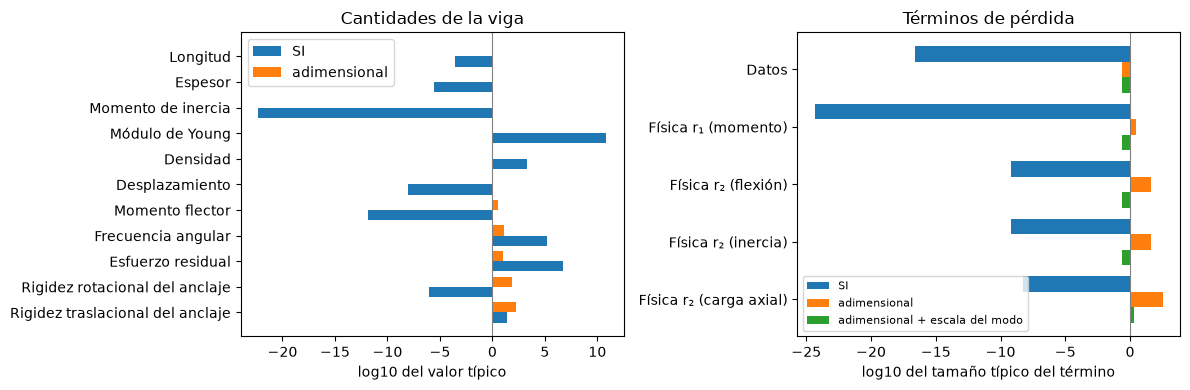

In [4]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))

orden = np.arange(len(tabla))
ejes[0].barh(orden + 0.2, np.log10(tabla["si"]), height=0.4, label="SI")
ejes[0].barh(orden - 0.2, np.log10(tabla["adimensional"].astype(float)), height=0.4, label="adimensional")
ejes[0].set_yticks(orden, tabla["cantidad"])
ejes[0].invert_yaxis()
ejes[0].set_xlabel("log10 del valor típico")
ejes[0].set_title("Cantidades de la viga")
ejes[0].legend()

orden = np.arange(len(perdidas))
for j, (col, nombre) in enumerate((("si", "SI"), ("adimensional", "adimensional"), ("pinn", "adimensional + escala del modo"))):
    ejes[1].barh(orden + (j - 1) * 0.27, np.log10(perdidas[col]), height=0.27, label=nombre)
ejes[1].set_yticks(orden, perdidas["termino"])
ejes[1].invert_yaxis()
ejes[1].set_xlabel("log10 del tamaño típico del término")
ejes[1].set_title("Términos de pérdida")
ejes[1].legend(fontsize=8, loc="lower left")
for ax in ejes:
    ax.axvline(0, color="gray", lw=0.8)
fig.tight_layout()
plt.show()

En SI las cantidades abarcan más de 30 órdenes de magnitud y los términos de pérdida unos 16. En forma adimensional, todo queda entre 1 y unos cientos; con la escala del modo, los términos de pérdida quedan prácticamente en el mismo nivel (entre 0.25 y 2).

## 2. La técnica: adimensionalizar

Adimensionalizar es dividir cada cantidad entre una escala de la propia viga, elegida para que las ecuaciones queden sin constantes físicas:

| Cantidad | Variable adimensional | Escala |
|---|---|---|
| Posición $x$ | $\xi = x/L$ | Longitud de la viga |
| Desplazamiento $w$ | $W = w/h$ (o normalizado a pico 1) | Espesor |
| Momento flector $M$ | $\hat{M} = M L^2/(E I h)$ | Rigidez a flexión |
| Frecuencia $\omega$ | $\lambda = \omega^2 \rho A L^4/(E I)$ | Frecuencia natural de la viga |
| Esfuerzo residual $\sigma_0$ | $n = \sigma_0 A L^2/(E I)$ | Carga de pandeo |
| Rigidez del anclaje $k_\theta$, $k_u$ | $\kappa_\theta = k_\theta L/(E I)$, $\kappa_u = k_u L^3/(E I)$ | Rigidez de la viga |
| Módulo de Young $E$ | $\theta = E/E_{ref}$ | Valor nominal del material |

Con estos grupos, las dos ecuaciones que usa la PINN quedan simplemente

$$\hat{M} - W'' = 0, \qquad \hat{M}'' - n\,W'' - \lambda\,W = 0,$$

donde la prima indica derivada respecto de $\xi$. Son los mismos grupos con los que trabaja el eigensolver por dentro, así que el método de referencia y la PINN usan exactamente la misma interfaz.

La celda siguiente comprueba dos cosas: que el $\lambda$ que calcula el eigensolver es el que se obtiene al adimensionalizar su frecuencia, y que la conversión de ida y vuelta recupera los valores originales sin pérdida.

In [5]:
modos = resolver_modos(VIGA, "voladizo", n_modos=3)
print("λ del eigensolver:          ", np.round(modos.lam, 4))
print("λ adimensionalizando ω:     ", np.round(ESC.a_lambda(modos.omega), 4))

viga_tensa = Viga(E=70e9, L=300e-6, b=28e-6, h=2.743e-6, rho=2200.0, sigma0=-5e6)
adim = escalar(viga_tensa, modos.omega, k_theta=1e-7, k_u=5.0)
vuelta = desescalar(adim, viga_tensa)
print("Error relativo de ida y vuelta en ω:  ", np.max(np.abs(vuelta["omega"] / modos.omega - 1)))
print("Error relativo de ida y vuelta en σ₀: ", abs(vuelta["sigma0"] / viga_tensa.sigma0 - 1))

λ del eigensolver:           [  12.3624  485.5188 3806.5463]
λ adimensionalizando ω:      [  12.3624  485.5188 3806.5463]
Error relativo de ida y vuelta en ω:   0.0
Error relativo de ida y vuelta en σ₀:  2.220446049250313e-16


## 3. Por qué no min-max ni estandarización

Las técnicas de escalamiento del curso (min-max, que lleva cada variable a $[0, 1]$, y la estandarización, que le resta su media y la divide entre su desviación estándar) funcionan bien para características de una tabla, pero aquí fallan por tres razones:

1. **Dependen de la muestra.** Los factores de escala salen de los datos (su mínimo, máximo, media o desviación), así que dos mediciones de la misma viga, con distinto ruido o distintos puntos, quedan escaladas de forma distinta. La adimensionalización solo depende de la geometría y del material nominal.
2. **Rompen las ecuaciones.** Min-max resta el mínimo: la condición "la viga no se mueve en el anclaje", $W(0) = 0$, deja de cumplirse, y la ecuación de movimiento gana un término constante que no tiene sentido físico. Con la adimensionalización las ecuaciones conservan su forma exacta.
3. **No comparten escala entre métodos.** Cada método tendría su propia escala según sus datos; con la adimensionalización el eigensolver, la inversión clásica y la PINN trabajan con los mismos números, y la comparación entre ellos es justa.

La celda siguiente lo muestra con dos mediciones simuladas de la misma viga, que solo difieren en el ruido.

In [6]:
config = cargar_config(CONFIGS / "m0_voladizo.yaml")
filas = []
for semilla in (0, 1):
    config["ruido"]["semilla"] = semilla
    conjunto = generar(config)
    w = conjunto.w[1] * 10e-9  # segundo modo, amplitud de 10 nm
    filas.append({
        "medición": f"semilla {semilla}",
        "escala min-max (nm)": 1e9 * (w.max() - w.min()),
        "W(0) con min-max": (w[0] - w.min()) / (w.max() - w.min()),
        "W(0) estandarizado": (w[0] - w.mean()) / w.std(),
        "W(0) adimensional": w[0] / 10e-9,
        "λ adimensional": ESC.a_lambda(conjunto.omega[1]),
    })
pd.DataFrame(filas).set_index("medición")

,escala min-max (nm),W(0) con min-max,W(0) estandarizado,W(0) adimensional,λ adimensional
medición,,,,,
semilla 0,17.3,0.579,-0.434,0.0101,486
semilla 1,17.5,0.576,-0.485,-0.013,485


Usamos el segundo modo, que tiene desplazamientos positivos y negativos. En el anclaje la viga no se mueve, así que $W(0)$ debería valer cero:

- Con **min-max**, el anclaje queda en casi 0.6, y la escala (el rango de cada muestra) cambia con el ruido.
- Con la **estandarización**, el anclaje queda en un valor que depende de la media y la desviación de esa muestra en particular.
- En forma **adimensional**, el anclaje queda en cero salvo el ruido de la propia medición, y $\lambda$ solo cambia lo que cambia la frecuencia medida.

## 4. Transformación logarítmica de la rigidez del anclaje y de E

La rigidez adimensional del anclaje, $\kappa_\theta$, recorre más de un orden de magnitud entre las severidades de nuestros datos sintéticos, y vale infinito en el soporte perfecto:

In [7]:
severidades = pd.DataFrame(
    [{"severidad": f"s{i}", "κ_θ": cargar_config(CONFIGS / f"m1_voladizo_s{i}.yaml")["soporte"]["kappa_theta"]}
     for i in range(1, 7)]
).set_index("severidad")
severidades["ln κ_θ"] = np.log(severidades["κ_θ"])
severidades

,κ_θ,ln κ_θ
severidad,,
s1,396,5.98
s2,156,5.05
s3,76.1,4.33
s4,36.1,3.59
s5,22.8,3.13
s6,12.1,2.49


En escala lineal, casi toda la variación de la frecuencia ocurre cuando $\kappa_\theta$ es pequeño; para valores grandes la curva se aplana y un paso fijo del optimizador significa cosas muy distintas según dónde esté. En escala logarítmica la curva es suave en todo el rango.

La gráfica de la derecha muestra la **elasticidad** $\partial \ln \lambda / \partial \ln \kappa_\theta$: cuánto cambia la frecuencia (en %) por cada 1 % de cambio en la rigidez. Para $E$ esa misma cantidad vale exactamente −1 en cualquier punto, porque $\lambda$ es proporcional a $1/E$. Trabajar en $\ln E$ y $\ln \kappa_\theta$ hace que:

- un paso del optimizador sea un **cambio porcentual**, comparable en cualquier rango;
- las sensibilidades de los dos parámetros sean números sin unidades y comparables entre sí (por eso el análisis de cuánta información aportan los datos usa $\ln E$ y $\ln \kappa_\theta$);
- los parámetros sean siempre positivos sin tener que imponerlo aparte.

La PINN aplica la misma idea: el parámetro que entrena es $\ln \theta = \ln(E/E_{ref})$.

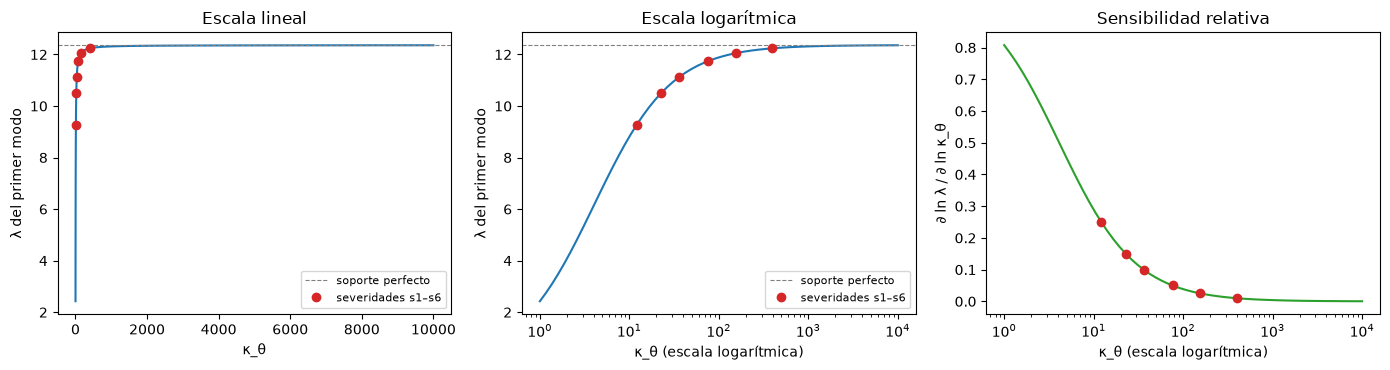

In [8]:
kappas = np.logspace(0, 4, 60)
lam1 = [resolver_modos(VIGA, "voladizo", Soporte(kappa_theta=k), n_modos=1).lam[0] for k in kappas]
lam_ideal = resolver_modos(VIGA, "voladizo", n_modos=1).lam[0]
elasticidad = elasticidad_kappa(VIGA, "voladizo", kappas)

fig, ejes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, escala in zip(ejes[:2], ("linear", "log")):
    ax.plot(kappas, lam1, "C0-")
    ax.axhline(lam_ideal, color="gray", ls="--", lw=0.8, label="soporte perfecto")
    ax.plot(severidades["κ_θ"], [np.interp(k, kappas, lam1) for k in severidades["κ_θ"]], "o", color="C3", label="severidades s1–s6")
    ax.set_xscale(escala)
    ax.set_xlabel("κ_θ" + (" (escala logarítmica)" if escala == "log" else ""))
    ax.set_ylabel("λ del primer modo")
    ax.legend(fontsize=8)
ejes[0].set_title("Escala lineal")
ejes[1].set_title("Escala logarítmica")
ejes[2].semilogx(kappas, elasticidad, "C2-")
ejes[2].plot(severidades["κ_θ"], np.interp(severidades["κ_θ"], kappas, elasticidad), "o", color="C3")
ejes[2].set_xlabel("κ_θ (escala logarítmica)")
ejes[2].set_ylabel("∂ ln λ / ∂ ln κ_θ")
ejes[2].set_title("Sensibilidad relativa")
fig.tight_layout()
plt.show()

La sensibilidad relativa cae de forma suave de 0.25 (anclaje muy flexible, s6) a 0.01 (casi perfecto, s1): en s3, por ejemplo, ignorar el anclaje cambia la frecuencia alrededor de 5 %, que es justo el nivel de severidad con que se diseñaron los datos.

## 5. Conclusión

- **Técnica elegida:** adimensionalización con escalas físicas de la viga, más la transformación logarítmica de $E$ y $\kappa_\theta$.
- **Efecto:** las cantidades pasan de abarcar más de 30 órdenes de magnitud a quedar entre 1 y unos cientos, y los términos de pérdida de la PINN pasan de unos 16 órdenes de magnitud a quedar todos entre 0.25 y 2.
- **Por qué esta y no min-max o estandarización:** no depende de la muestra, conserva las ecuaciones y sus condiciones de frontera, y es la misma escala para todos los métodos, lo que hace justa su comparación.
- **Por qué el logaritmo:** la rigidez del anclaje varía en órdenes de magnitud; en escala logarítmica los pasos del optimizador son cambios porcentuales y las sensibilidades de $E$ y $\kappa_\theta$ quedan comparables.